# 1. Dataset Loading + Initial Exploration

In [1]:
import pandas as pd
df = pd.read_csv('/kaggle/input/datasets/lyesaitk/house-train/train.csv')

In [2]:
print("=== Shape of the dataset ===")
print(df.shape)

=== Shape of the dataset ===
(1460, 81)


In [3]:
print("\n=== First 5 rows (head) ===")
print(df.head())


=== First 5 rows (head) ===
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  Sale

In [4]:
print("\n=== Dataset Information (info) ===")
df.info()


=== Dataset Information (info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1

In [5]:
print("\n=== Statistical Summary of Numerical Columns (describe) ===")
print(df.describe())


=== Statistical Summary of Numerical Columns (describe) ===
                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.11

# 2. MISSING VALUES

In [6]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_percent = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

missing_df = pd.DataFrame({
    'missing_count' : missing ,
    'missing_percentage' : missing_percent
}) 

print("==== TOTAL DATASET COLUMNS ==")
print(len(df))
print(" ==== TOTAL COLUMNS WITH MISSING VALUES ==== ")
print(len(missing_df[missing_df['missing_count'] > 0]))

==== TOTAL DATASET COLUMNS ==
1460
 ==== TOTAL COLUMNS WITH MISSING VALUES ==== 
19


# 3. CORRELATION HEATMAP

==== TOP CORRELATED FEATURES ====
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


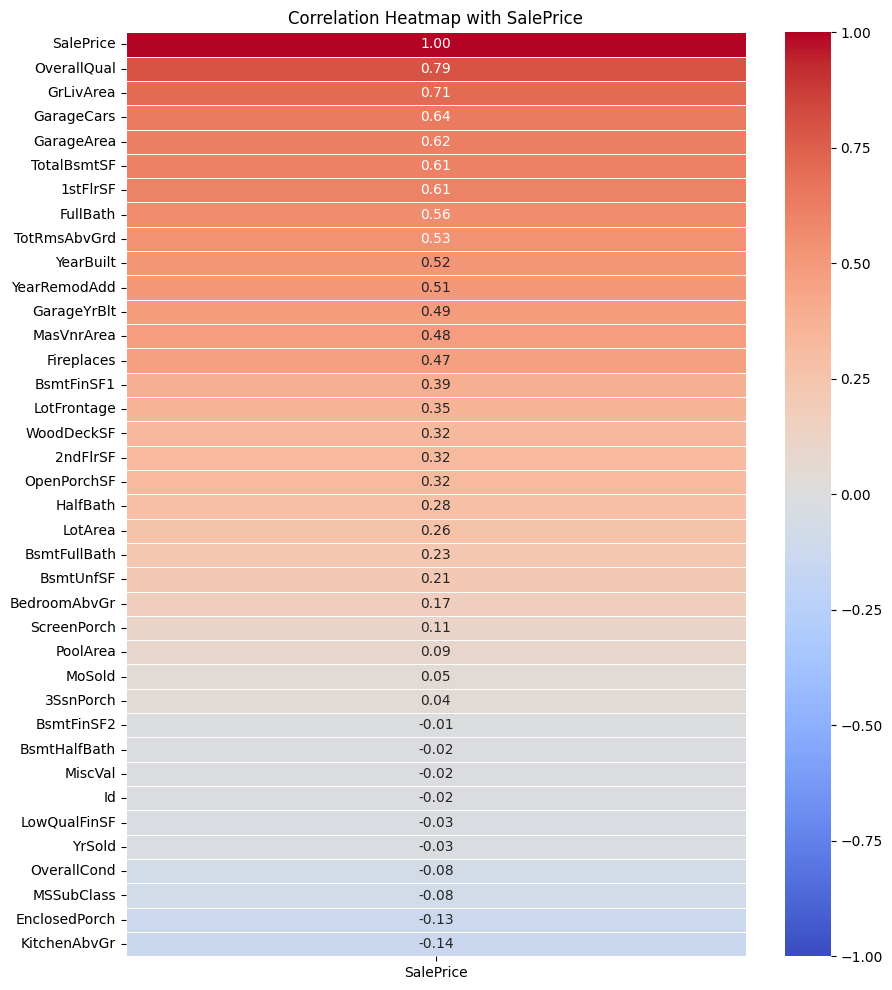

In [7]:
import numpy  as np
import matplotlib.pyplot as plt
import seaborn as sns

print("==== TOP CORRELATED FEATURES ====")
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix=numeric_df.corr()
top_corr = corr_matrix['SalePrice'].abs().sort_values(ascending=False).head(15)
print(top_corr)

plt.figure(figsize=(10,12))
sns.heatmap(corr_matrix[['SalePrice']].sort_values(by='SalePrice', ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, fmt='.2f')
plt.title("Correlation Heatmap with SalePrice")
plt.show()

# 4. VISUALIZE IMPORTANT FEATURES

 ==== MOST IMPORTANT FEATURES ==== 


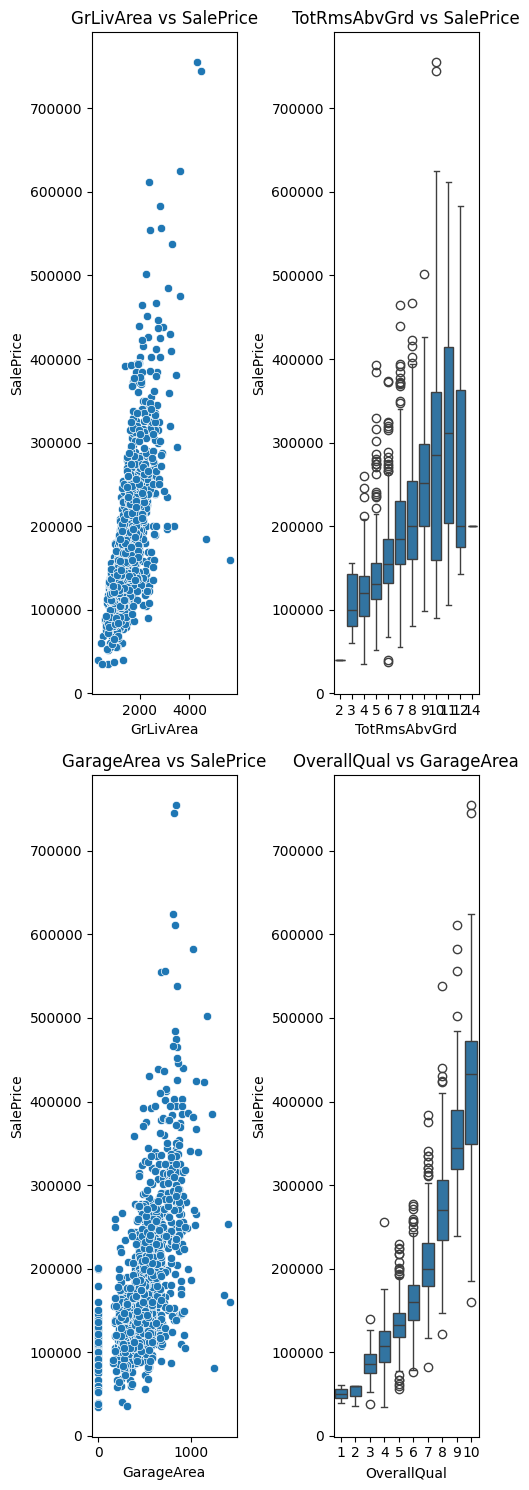

In [8]:
print(" ==== MOST IMPORTANT FEATURES ==== ")
fig ,axes = plt.subplots(2 ,2 ,figsize=(5,15))
sns.scatterplot(x='GrLivArea' ,y='SalePrice' ,data=df ,ax=axes[0,0])
axes[0,0].set_title('GrLivArea vs SalePrice')

sns.boxplot(x='TotRmsAbvGrd' ,y='SalePrice' ,data=df ,ax=axes[0,1])
axes[0,1].set_title('TotRmsAbvGrd vs SalePrice')

sns.scatterplot(x='GarageArea' ,y='SalePrice' ,data=df ,ax=axes[1,0])
axes[1,0].set_title('GarageArea vs SalePrice')

sns.boxplot(x='OverallQual' ,y='SalePrice' ,data=df ,ax=axes[1,1])
axes[1,1].set_title('OverallQual vs GarageArea')

plt.tight_layout()
plt.show()